In [ ]:
def unpack_kv_cache(kv_cache):
    """Convert DynamicCache or other cache formats into standard ((k,v),(k,v),...) format."""
    if kv_cache is None:
        return None
    # Newest transformers: DynamicCache has .layers list of DynamicLayer objects
    if hasattr(kv_cache, "layers") and isinstance(kv_cache.layers, list):
        return [(layer.keys, layer.values) for layer in kv_cache.layers]
    # Legacy tuple format
    if isinstance(kv_cache, (tuple, list)):
        return kv_cache
    raise TypeError(f"Unsupported KV cache type: {type(kv_cache)}")


def get_seq_len(kv_cache):
    """Return current sequence length of KV cache."""
    layers = unpack_kv_cache(kv_cache)
    if layers is None or len(layers) == 0:
        return 0
    return layers[0][0].shape[-2]


def kv_cache_size_mb(kv_cache):
    """Compute total KV cache memory size in MB."""
    layers = unpack_kv_cache(kv_cache)
    if layers is None:
        return 0
    total = 0
    for k, v in layers:
        total += k.nelement() * k.element_size()
        total += v.nelement() * v.element_size()
    return total / (1024 ** 2)


def offload_kv_to_cpu_pinned(kv_cache):
    """Move KV cache to pinned CPU memory for async transfer."""
    layers = unpack_kv_cache(kv_cache)
    return tuple(
        (k.detach().contiguous().cpu().pin_memory(),
         v.detach().contiguous().cpu().pin_memory())
        for k, v in layers
    )


def extract_new_kv_chunk_pinned(full_kv_cache, old_seq_len):
    """Extract only newly generated KV entries and store in pinned CPU memory."""
    layers = unpack_kv_cache(full_kv_cache)
    return tuple(
        (k[:, :, old_seq_len:, :].detach().contiguous().cpu().pin_memory(),
         v[:, :, old_seq_len:, :].detach().contiguous().cpu().pin_memory())
        for k, v in layers
    )


def append_kv_chunk_pinned(cpu_kv_cache, new_chunk):
    """Append new KV chunk to CPU-side KV cache, keeping result in pinned memory."""
    return tuple(
        (torch.cat([old_k, new_k], dim=-2).contiguous().pin_memory(),
         torch.cat([old_v, new_v], dim=-2).contiguous().pin_memory())
        for (old_k, old_v), (new_k, new_v) in zip(cpu_kv_cache, new_chunk)
    )


def build_kv_cache(kv_layers):
    """Reconstruct a DynamicCache from a list of (key, value) tensor pairs."""
    cache = DynamicCache()
    for layer_idx, (k, v) in enumerate(kv_layers):
        cache.update(k, v, layer_idx)
    return cache

In [ ]:
def run_dejavu_prefetch_benchmark():
    microbatches_count = [8, 16,32]
    n_tokens = [256, 512]
    results = []

    total_vram_mb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 2)

    for D in microbatches_count:
        for N in n_tokens:

            prompts = long_prompts[:D]

            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

            total_start = time.perf_counter()

            with torch.no_grad():

                # PREFILL
                kv_caches = []
                next_tokens = []
                for i in range(D):
                    inputs = tokenizer(prompts[i], return_tensors="pt").to(device)
                    outputs = model(input_ids=inputs.input_ids, use_cache=True)
                    kv_caches.append(outputs.past_key_values)
                    next_tokens.append(torch.argmax(outputs.logits[:, -1, :], dim=1).unsqueeze(1))

                # Offload all KV caches to pinned CPU memory
                cpu_kv_caches = [offload_kv_to_cpu_pinned(kv) for kv in kv_caches]
                del kv_caches
                torch.cuda.empty_cache()

                prefetch_stream = torch.cuda.Stream()
                offload_stream = torch.cuda.Stream()

                # Prefetch first microbatch before loop
                with torch.cuda.stream(prefetch_stream):
                    prefetched = [(k.to(device, non_blocking=True), v.to(device, non_blocking=True))
                                  for k, v in cpu_kv_caches[0]]

                # DECODE
                for step in range(N - 1):
                    for i in range(D):
                        next_i = (i + 1) % D

                        prefetch_stream.synchronize()
                        offload_stream.synchronize()

                        gpu_layers = prefetched

                        with torch.cuda.stream(prefetch_stream):
                            prefetched = [(k.to(device, non_blocking=True), v.to(device, non_blocking=True))
                                          for k, v in cpu_kv_caches[next_i]]

                        gpu_cache = build_kv_cache(gpu_layers)
                        old_seq_len = gpu_cache.get_seq_length()
                        outputs = model(
                            input_ids=next_tokens[i],
                            past_key_values=gpu_cache,
                            use_cache=True
                        )

                        with torch.cuda.stream(offload_stream):
                            new_chunk = extract_new_kv_chunk_pinned(outputs.past_key_values, old_seq_len)
                            cpu_kv_caches[i] = append_kv_chunk_pinned(cpu_kv_caches[i], new_chunk)

                        next_tokens[i] = torch.argmax(outputs.logits[:, -1, :], dim=1).unsqueeze(1)

                try:
                    del gpu_cache, new_chunk
                except:
                    pass
                torch.cuda.empty_cache()

            total_end = time.perf_counter()

            latency = total_end - total_start
            throughput = (D * N) / latency
            peak_vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
            vram_util = (peak_vram_mb / total_vram_mb) * 100
            cpu_kv_mb = sum(kv_cache_size_mb(cache) for cache in cpu_kv_caches)

            print(f"D={D:<4} N={N:<4} | Latency={latency:.3f}s | Throughput={throughput:.1f} tok/s | "
                  f"Peak VRAM={peak_vram_mb:.1f}MB | VRAM%={vram_util:.1f}% | CPU KV Cache={cpu_kv_mb:.1f}MB")

            results.append({
                "Microbatches (D)": D,
                "Tokens Generated (N)": N,
                "Latency (s)": latency,
                "Throughput (tok/s)": throughput,
                "Peak VRAM (MB)": peak_vram_mb,
                "VRAM Util (%)": vram_util,
                "CPU KV Cache Total (MB)": cpu_kv_mb
            })

            del next_tokens
            torch.cuda.empty_cache()

    return pd.DataFrame(results)

In [ ]:
def run_dejavu_benchmark():
  microbatches_count = [8,16,32]
  n_tokens = [256,512]
  # microbatches_count = [2]
  # n_tokens = [32]
  results = []

  total_vram_mb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 2)

  for D in microbatches_count:
    for N in n_tokens:

      prompts = long_prompts[:D] # Select D prompts

      torch.cuda.empty_cache()
      torch.cuda.reset_peak_memory_stats()

      total_start= time.perf_counter()

      with torch.no_grad():
        # PREFILL
        for i in range(D):
          inputs = tokenizer(prompts[i], return_tensors="pt").to(device)
          outputs = model(input_ids = inputs.input_ids,use_cache = True)
          kv_caches.append(outputs.past_key_values)
          next_token = torch.argmax(outputs.logits[:,-1,:],dim=1).unsqueeze(1)
          next_tokens.append(next_token)

        # Move KV cache to CPU
        cpu_kv_caches = []
        for i in range(D):
          layers = get_kv_layers(kv_caches[i])
          cpu_layers = [(k.detach().cpu(), v.detach().cpu()) for k, v in layers]
          cpu_kv_caches.append(cpu_layers)

        del kv_caches
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        # PREFILL
        cpu_kv_caches = []
        next_tokens = []
        for i in range(D):
            inputs = tokenizer(prompts[i], return_tensors="pt").to(device)
            outputs = model(input_ids=inputs.input_ids, use_cache=True)
            next_tokens.append(torch.argmax(outputs.logits[:, -1, :], dim=1).unsqueeze(1))
            layers = get_kv_layers(outputs.past_key_values)
            cpu_kv_caches.append([(k.detach().cpu(), v.detach().cpu()) for k, v in layers])
            del outputs
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        transfer_time = 0.0
        # DECODE
        for step in range(N-1):
          for i in range(D):
            # Transfer KV cache from CPU to GPU
            gpu_cache, t_upload = move_full_kv_to_device_timed(cpu_kv_caches[i], device)
            old_seq_length = get_cache_seq_len(gpu_cache)
            outputs = model(
                input_ids = next_tokens[i],
                past_key_values = gpu_cache,
                use_cache = True
              )
            new_kv_chunk = extract_new_kv_chunk(outputs.past_key_values, old_seq_length)

            # Append newly generated kv chunk to the cpu cache
            t_start = time.perf_counter()
            cpu_kv_caches[i] = append_kv_caches(cpu_kv_caches[i], new_kv_chunk)
            t_stop = time.perf_counter()
            t_offload = t_stop - t_start

            next_tokens[i] = torch.argmax(outputs.logits[:,-1,:],dim=1).unsqueeze(1)

            transfer_time += t_upload
            transfer_time += t_offload

            torch.cuda.empty_cache()

        del gpu_cache, new_kv_chunk
        torch.cuda.empty_cache()
      total_end = time.perf_counter()

      # METRICS
      latency = total_end - total_start
      total_tokens = D * N
      throughput = total_tokens / latency
      peak_vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
      vram_util = (peak_vram_mb / total_vram_mb) * 100
      transfer_overhead = (transfer_time / latency) * 100

      total_kv_bytes = 0
      for cache in cpu_kv_caches:
        for k, v in cache:
          total_kv_bytes += k.nelement() * k.element_size()
          total_kv_bytes += v.nelement() * v.element_size()
      cpu_kv_cache_mb = total_kv_bytes / (1024 ** 2)

      print(f"D={D:<4} N={N:<4} | Latency={latency:.3f}s | Throughput={throughput:.1f} tok/s | Peak VRAM={peak_vram_mb:.1f}MB | VRAM%={vram_util:.1f}% | CPU KV Cache={cpu_kv_cache_mb:.1f}MB | Transfer Time={transfer_time:.2f}s | Transfer Overhead={transfer_overhead:.2f}%")

      results.append({
                "Microbatches (D)": D,
                "Tokens Generated (N)": N,
                "Latency (s)": latency,
                "Throughput (tok/s)": throughput,
                "Peak VRAM (MB)": peak_vram_mb,
                "VRAM Util (%)": vram_util,
                "CPU KV Cache Total (MB)": cpu_kv_cache_mb,
                "Transfer Time (s)": transfer_time,
                "Transfer Overhead (%)": transfer_overhead,
            })

      # CLEANUP
      del next_tokens
      torch.cuda.empty_cache()

  return pd.DataFrame(results)



In [ ]:
def run_h2o_dejavu_prefetch_benchmark(budget_ratio=0.4, recent_ratio=0.5):
    microbatches_count = [8, 16,32]
    n_tokens = [256, 512]
    results = []

    total_vram_mb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 2)
    num_layers = model.config.num_hidden_layers

    for D in microbatches_count:
        for N in n_tokens:

            prompts = long_prompts[:D]
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

            # Compute budget per microbatch
            sample_len = tokenizer(prompts[0], return_tensors="pt").input_ids.shape[1]
            budget = int((sample_len + N) * budget_ratio)
            budget = max(budget, sample_len)
            recent_window = int(budget * recent_ratio)

            total_start = time.perf_counter()

            with torch.no_grad():
                next_tokens = []
                cpu_kv_caches = []
                cum_scores_list = []

                # PREFILL
                for i in range(D):
                    inputs = tokenizer(prompts[i], return_tensors="pt").to(device)
                    outputs = model(
                        input_ids=inputs.input_ids,
                        use_cache=True,
                        output_attentions=True
                    )
                    next_token = torch.argmax(outputs.logits[:, -1, :], dim=1).unsqueeze(1)
                    next_tokens.append(next_token)

                    # Initialize cumulative scores
                    seq_len = outputs.past_key_values.get_seq_length()
                    scores = torch.zeros(seq_len, device=device)
                    for attn in outputs.attentions:
                        scores += attn[0].sum(dim=0).sum(dim=0)
                    cum_scores_list.append(scores)

                    # Offload to pinned CPU memory
                    cpu_kv_caches.append(offload_kv_to_cpu_pinned(outputs.past_key_values))

                prefetch_stream = torch.cuda.Stream()
                offload_stream = torch.cuda.Stream()

                # Prefetch first microbatch
                with torch.cuda.stream(prefetch_stream):
                    prefetched = tuple(
                        (k.to(device, non_blocking=True), v.to(device, non_blocking=True))
                        for k, v in cpu_kv_caches[0]
                    )

                # DECODE
                for step in range(N - 1):
                    for i in range(D):
                        next_i = (i + 1) % D

                        prefetch_stream.synchronize()
                        offload_stream.synchronize()

                        gpu_layers = prefetched

                        # Prefetch next microbatch
                        with torch.cuda.stream(prefetch_stream):
                            prefetched = tuple(
                                (k.to(device, non_blocking=True), v.to(device, non_blocking=True))
                                for k, v in cpu_kv_caches[next_i]
                            )

                        # Build cache and decode
                        gpu_cache = build_kv_cache(gpu_layers)
                        outputs = model(
                            input_ids=next_tokens[i],
                            past_key_values=gpu_cache,
                            use_cache=True,
                            output_attentions=True
                        )
                        next_tokens[i] = torch.argmax(outputs.logits[:, -1, :], dim=1).unsqueeze(1)

                        # Update cumulative scores
                        kv = outputs.past_key_values
                        current_len = kv.get_seq_length()
                        new_score = torch.zeros(1, device=device)
                        cum_scores_list[i] = torch.cat([cum_scores_list[i], new_score])
                        for attn in outputs.attentions:
                            step_scores = attn[0].sum(dim=0).sum(dim=0)
                            if len(step_scores) == len(cum_scores_list[i]):
                                cum_scores_list[i] += step_scores

                        # H2O eviction — one at a time
                        while current_len > budget:
                            evict_candidates = cum_scores_list[i][:-recent_window].clone()
                            if len(evict_candidates) == 0:
                                break

                            evict_pos = evict_candidates.argmin().item()

                            keep_mask = torch.ones(current_len, dtype=torch.bool, device=device)
                            keep_mask[evict_pos] = False
                            keep_indices = torch.where(keep_mask)[0]

                            kv_layers = unpack_kv_cache(kv)
                            kept_layers = [(k[:, :, keep_indices, :], v[:, :, keep_indices, :]) for k, v in kv_layers]
                            kv = build_kv_cache(kept_layers)

                            cum_scores_list[i] = cum_scores_list[i][keep_mask]
                            current_len -= 1

                        # Offload evicted cache to pinned CPU
                        with torch.cuda.stream(offload_stream):
                            cpu_kv_caches[i] = tuple(
                                (k.detach().contiguous().cpu().pin_memory(),
                                 v.detach().contiguous().cpu().pin_memory())
                                for k, v in unpack_kv_cache(kv)
                            )

                        del gpu_layers, gpu_cache, outputs, kv

            total_end = time.perf_counter()

            latency = total_end - total_start
            throughput = (D * N) / latency
            peak_vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
            vram_util = (peak_vram_mb / total_vram_mb) * 100

            cpu_kv_mb = sum(
                k.nelement() * k.element_size() + v.nelement() * v.element_size()
                for cache in cpu_kv_caches for k, v in cache
            ) / (1024 ** 2)

            print(f"D={D:<4} N={N:<4} | Budget={budget:<4} | Latency={latency:.3f}s | Throughput={throughput:.1f} tok/s | "
                  f"Peak VRAM={peak_vram_mb:.1f}MB | VRAM%={vram_util:.1f}% | CPU KV={cpu_kv_mb:.1f}MB")

            results.append({
                "Microbatches (D)": D,
                "Tokens Generated (N)": N,
                "Budget": budget,
                "Latency (s)": latency,
                "Throughput (tok/s)": throughput,
                "Peak VRAM (MB)": peak_vram_mb,
                "VRAM Util (%)": vram_util,
                "CPU KV (MB)": cpu_kv_mb,
            })

            del cpu_kv_caches, next_tokens, cum_scores_list, prefetched
            torch.cuda.empty_cache()

    return pd.DataFrame(results)

In [ ]:
def run_h2o_dejavu_prefetch_benchmark(budget_ratio=0.4, recent_ratio=0.5):
    microbatches_count = [8, 16,32]
    n_tokens = [256, 512]
    results = []

    total_vram_mb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 2)
    num_layers = model.config.num_hidden_layers

    for D in microbatches_count:
        for N in n_tokens:

            prompts = long_prompts[:D]
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

            # Compute budget per microbatch
            sample_len = tokenizer(prompts[0], return_tensors="pt").input_ids.shape[1]
            budget = int((sample_len + N) * budget_ratio)
            budget = max(budget, sample_len)
            recent_window = int(budget * recent_ratio)

            total_start = time.perf_counter()

            with torch.no_grad():
                next_tokens = []
                cpu_kv_caches = []
                cum_scores_list = []

                # PREFILL
                for i in range(D):
                    inputs = tokenizer(prompts[i], return_tensors="pt").to(device)
                    outputs = model(
                        input_ids=inputs.input_ids,
                        use_cache=True,
                        output_attentions=True
                    )
                    next_token = torch.argmax(outputs.logits[:, -1, :], dim=1).unsqueeze(1)
                    next_tokens.append(next_token)

                    # Initialize cumulative scores
                    seq_len = outputs.past_key_values.get_seq_length()
                    scores = torch.zeros(seq_len, device=device)
                    for attn in outputs.attentions:
                        scores += attn[0].sum(dim=0).sum(dim=0)
                    cum_scores_list.append(scores)

                    # Offload to pinned CPU memory
                    cpu_kv_caches.append(offload_kv_to_cpu_pinned(outputs.past_key_values))

                prefetch_stream = torch.cuda.Stream()
                offload_stream = torch.cuda.Stream()

                # Prefetch first microbatch
                with torch.cuda.stream(prefetch_stream):
                    prefetched = tuple(
                        (k.to(device, non_blocking=True), v.to(device, non_blocking=True))
                        for k, v in cpu_kv_caches[0]
                    )

                # DECODE
                for step in range(N - 1):
                    for i in range(D):
                        next_i = (i + 1) % D

                        prefetch_stream.synchronize()
                        offload_stream.synchronize()

                        gpu_layers = prefetched

                        # Prefetch next microbatch
                        with torch.cuda.stream(prefetch_stream):
                            prefetched = tuple(
                                (k.to(device, non_blocking=True), v.to(device, non_blocking=True))
                                for k, v in cpu_kv_caches[next_i]
                            )

                        # Build cache and decode
                        gpu_cache = build_kv_cache(gpu_layers)
                        outputs = model(
                            input_ids=next_tokens[i],
                            past_key_values=gpu_cache,
                            use_cache=True,
                            output_attentions=True
                        )
                        next_tokens[i] = torch.argmax(outputs.logits[:, -1, :], dim=1).unsqueeze(1)

                        # Update cumulative scores
                        kv = outputs.past_key_values
                        current_len = kv.get_seq_length()
                        new_score = torch.zeros(1, device=device)
                        cum_scores_list[i] = torch.cat([cum_scores_list[i], new_score])
                        for attn in outputs.attentions:
                            step_scores = attn[0].sum(dim=0).sum(dim=0)
                            if len(step_scores) == len(cum_scores_list[i]):
                                cum_scores_list[i] += step_scores

                        # H2O eviction — one at a time
                        while current_len > budget:
                            evict_candidates = cum_scores_list[i][:-recent_window].clone()
                            if len(evict_candidates) == 0:
                                break

                            evict_pos = evict_candidates.argmin().item()

                            keep_mask = torch.ones(current_len, dtype=torch.bool, device=device)
                            keep_mask[evict_pos] = False
                            keep_indices = torch.where(keep_mask)[0]

                            kv_layers = unpack_kv_cache(kv)
                            kept_layers = [(k[:, :, keep_indices, :], v[:, :, keep_indices, :]) for k, v in kv_layers]
                            kv = build_kv_cache(kept_layers)

                            cum_scores_list[i] = cum_scores_list[i][keep_mask]
                            current_len -= 1

                        # Offload evicted cache to pinned CPU
                        with torch.cuda.stream(offload_stream):
                            cpu_kv_caches[i] = tuple(
                                (k.detach().contiguous().cpu().pin_memory(),
                                 v.detach().contiguous().cpu().pin_memory())
                                for k, v in unpack_kv_cache(kv)
                            )

                        del gpu_layers, gpu_cache, outputs, kv

            total_end = time.perf_counter()

            latency = total_end - total_start
            throughput = (D * N) / latency
            peak_vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
            vram_util = (peak_vram_mb / total_vram_mb) * 100

            cpu_kv_mb = sum(
                k.nelement() * k.element_size() + v.nelement() * v.element_size()
                for cache in cpu_kv_caches for k, v in cache
            ) / (1024 ** 2)

            print(f"D={D:<4} N={N:<4} | Budget={budget:<4} | Latency={latency:.3f}s | Throughput={throughput:.1f} tok/s | "
                  f"Peak VRAM={peak_vram_mb:.1f}MB | VRAM%={vram_util:.1f}% | CPU KV={cpu_kv_mb:.1f}MB")

            results.append({
                "Microbatches (D)": D,
                "Tokens Generated (N)": N,
                "Budget": budget,
                "Latency (s)": latency,
                "Throughput (tok/s)": throughput,
                "Peak VRAM (MB)": peak_vram_mb,
                "VRAM Util (%)": vram_util,
                "CPU KV (MB)": cpu_kv_mb,
            })

            del cpu_kv_caches, next_tokens, cum_scores_list, prefetched
            torch.cuda.empty_cache()

    return pd.DataFrame(results)

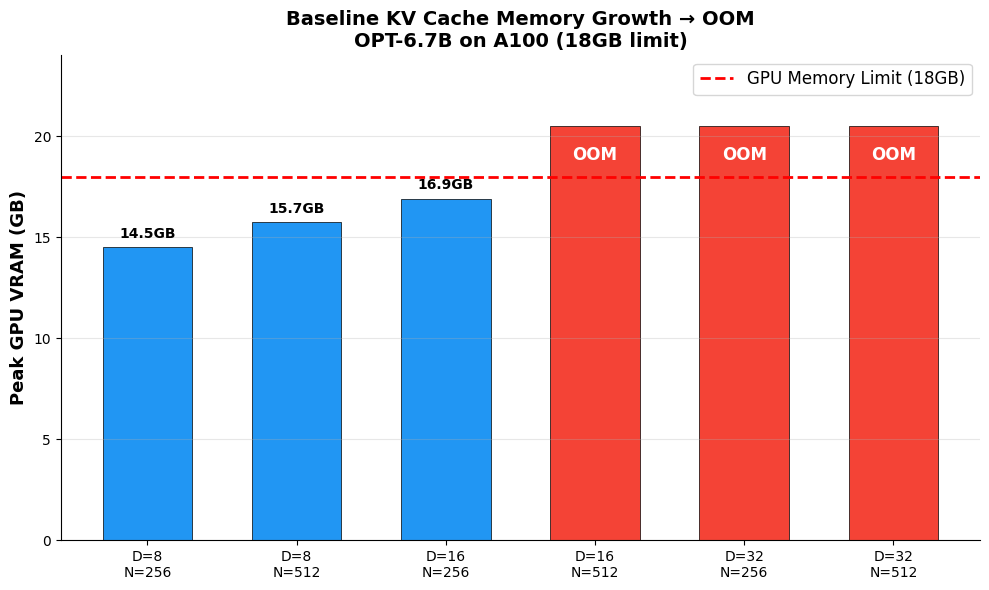

In [12]:
import matplotlib.pyplot as plt
import numpy as np

configs = ['D=8\nN=256', 'D=8\nN=512', 'D=16\nN=256', 'D=16\nN=512', 'D=32\nN=256', 'D=32\nN=512']

# Peak VRAM (MB) — None = OOM
vram = [14835, 16117, 17315, None, None, None]

# Memory limit
mem_limit = 20000  # 20GB in MB

fig, ax = plt.subplots(figsize=(10, 6))

colors = []
vals = []
for v in vram:
    if v is not None:
        vals.append(v / 1024)  # Convert to GB
        colors.append('#2196F3')
    else:
        vals.append(20.5)  # Show bar exceeding limit
        colors.append('#F44336')

bars = ax.bar(configs, vals, color=colors, edgecolor='black', linewidth=0.5, width=0.6)

# Memory limit line
ax.axhline(y=18, color='red', linestyle='--', linewidth=2, label='GPU Memory Limit (18GB)')

# Label bars
for i, (bar, v) in enumerate(zip(bars, vram)):
    if v is not None:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
                f'{v/1024:.1f}GB', ha='center', va='bottom', fontsize=10, fontweight='bold')
    else:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() - 1,
                'OOM', ha='center', va='top', fontsize=12, fontweight='bold', color='white')


ax.set_ylabel('Peak GPU VRAM (GB)', fontsize=13, fontweight='bold')
ax.set_title('Baseline KV Cache Memory Growth → OOM\nOPT-6.7B on A100 (18GB limit)', fontsize=14, fontweight='bold')
ax.set_ylim(0, 24)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('baseline_oom.png', dpi=150)

Saved per-token latency comparison
Saved throughput comparison
Saved VRAM comparison
Saved transfer overhead


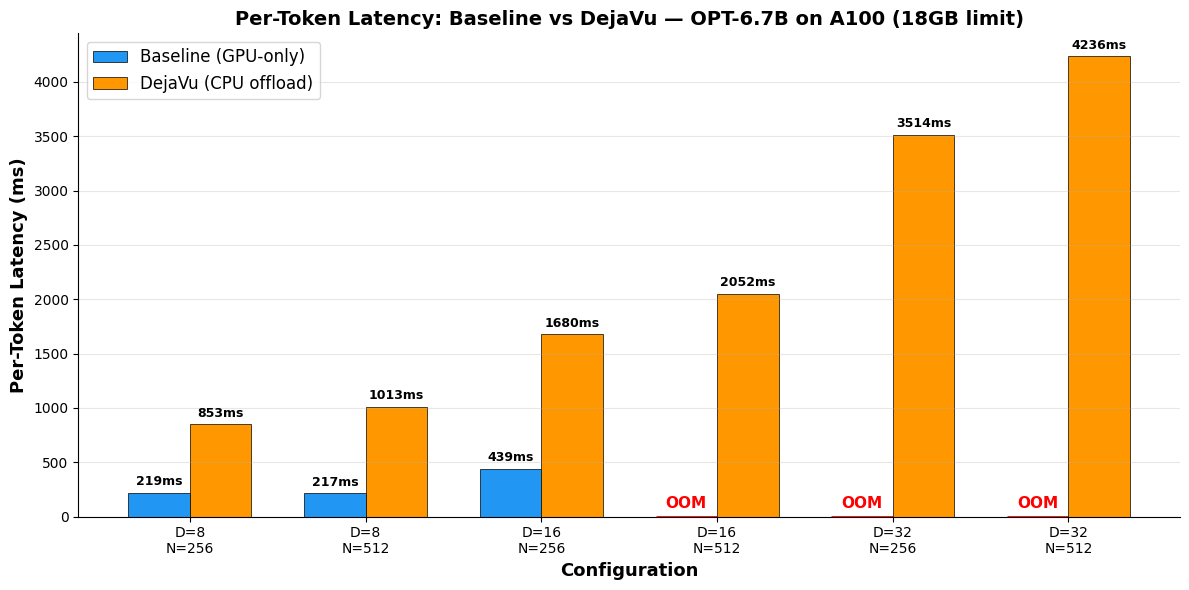

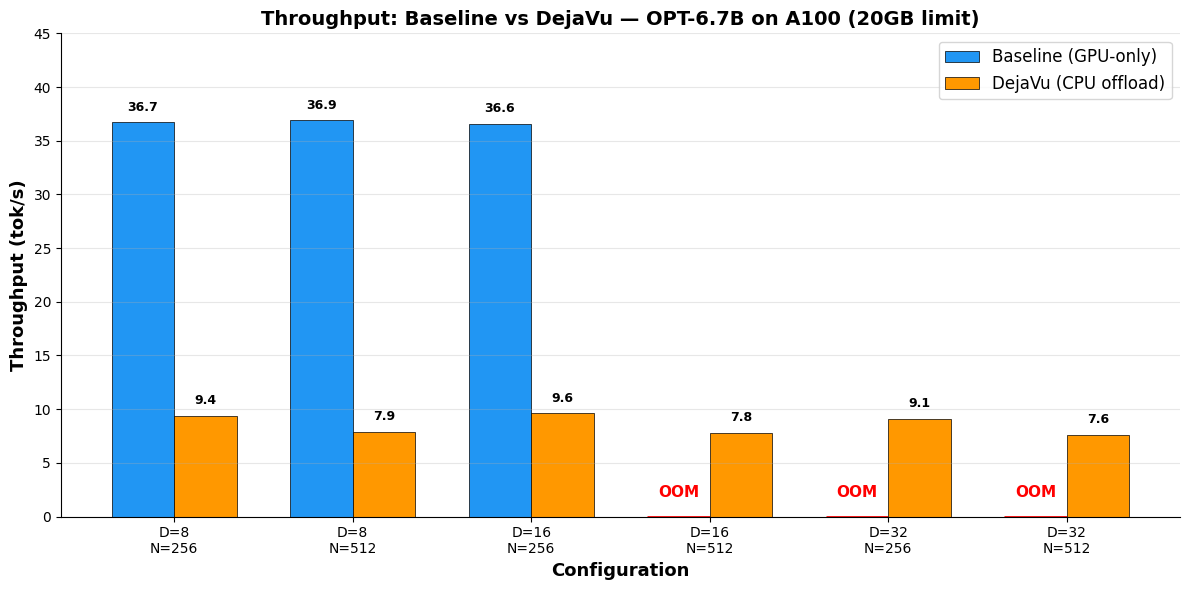

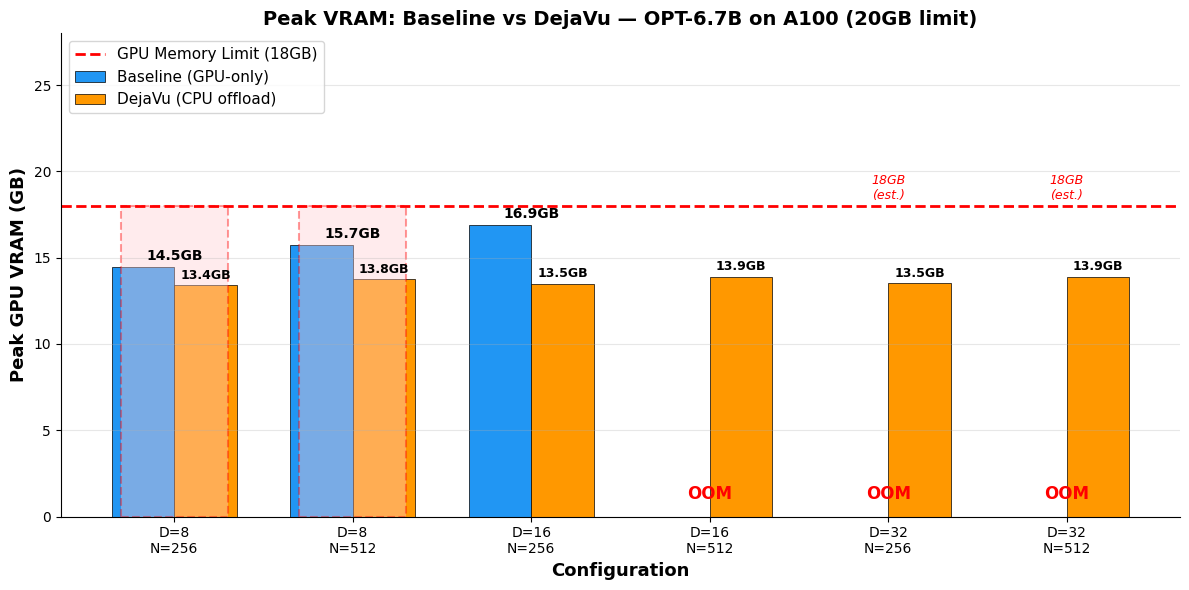

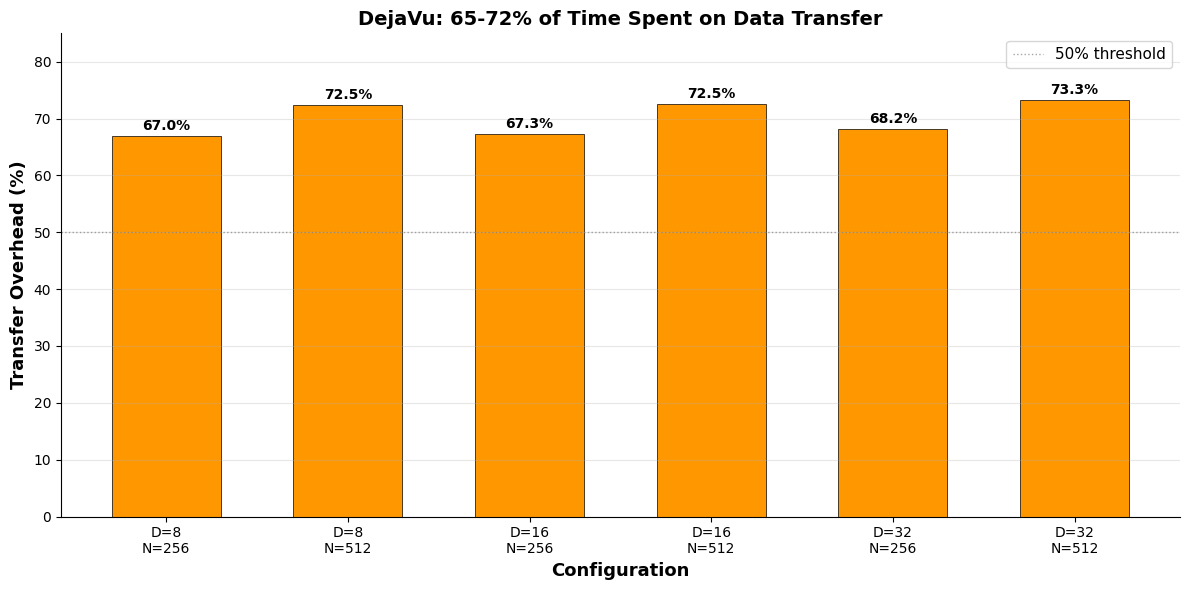

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================
# DATA
# ============================================
baseline = {
    'configs': ['D=8\nN=256', 'D=8\nN=512', 'D=16\nN=256', 'D=16\nN=512', 'D=32\nN=256', 'D=32\nN=512'],
    'throughput': [36.7, 36.9, 36.6, None, None, None],
    'latency': [55.8, 111.0, 112.0, None, None, None],
    'vram': [14835, 16117, 17315, None, None, None],
    'N': [256, 512, 256, 512, 256, 512],
}

dejavu = {
    'configs': ['D=8\nN=256', 'D=8\nN=512', 'D=16\nN=256', 'D=16\nN=512', 'D=32\nN=256', 'D=32\nN=512'],
    'throughput': [9.4, 7.9, 9.6, 7.8, 9.1, 7.6],
    'latency': [217.5, 517.4, 428.4, 1048.6, 896, 2164.5],
    'vram': [13716, 14080, 13819, 14216, 13853, 14234],
    'transfer_oh': [66.97, 72.48, 67.27, 72.52, 68.15, 73.26],
    'N': [256, 512, 256, 512, 256, 512],
}

# Compute per-token latency (ms)
baseline_per_token = [
    (l / (n-1)) * 1000 if l is not None else None
    for l, n in zip(baseline['latency'], baseline['N'])
]
dejavu_per_token = [
    (l / (n-1)) * 1000
    for l, n in zip(dejavu['latency'], dejavu['N'])
]

configs = baseline['configs']
x = np.arange(len(configs))
width = 0.35

# ============================================
# GRAPH 1: Per-Token Latency Comparison
# ============================================
fig, ax = plt.subplots(figsize=(12, 6))

b_vals = [v if v is not None else 0 for v in baseline_per_token]
d_vals = dejavu_per_token

bars1 = ax.bar(x - width/2, b_vals, width, label='Baseline (GPU-only)', color='#2196F3', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, d_vals, width, label='DejaVu (CPU offload)', color='#FF9800', edgecolor='black', linewidth=0.5)

# Mark OOMs
for i, v in enumerate(baseline_per_token):
    if v is None:
        ax.text(x[i] - width/2, 50, 'OOM', ha='center', va='bottom', fontsize=11, fontweight='bold', color='red')
        bars1[i].set_color('#FFCDD2')
        bars1[i].set_edgecolor('red')
        bars1[i].set_linewidth(2)
    else:
        ax.text(x[i] - width/2, v + 40, f'{v:.0f}ms', ha='center', va='bottom', fontsize=9, fontweight='bold')

for i, v in enumerate(d_vals):
    ax.text(x[i] + width/2, v + 40, f'{v:.0f}ms', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Per-Token Latency (ms)', fontsize=13, fontweight='bold')
ax.set_title('Per-Token Latency: Baseline vs DejaVu — OPT-6.7B on A100 (18GB limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved per-token latency comparison")

# ============================================
# GRAPH 2: Throughput Comparison
# ============================================
fig, ax = plt.subplots(figsize=(12, 6))

b_vals = [v if v is not None else 0 for v in baseline['throughput']]
d_vals = dejavu['throughput']

bars1 = ax.bar(x - width/2, b_vals, width, label='Baseline (GPU-only)', color='#2196F3', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, d_vals, width, label='DejaVu (CPU offload)', color='#FF9800', edgecolor='black', linewidth=0.5)

for i, v in enumerate(baseline['throughput']):
    if v is None:
        ax.text(x[i] - width/2, 1.5, 'OOM', ha='center', va='bottom', fontsize=11, fontweight='bold', color='red')
        bars1[i].set_color('#FFCDD2')
        bars1[i].set_edgecolor('red')
        bars1[i].set_linewidth(2)
    else:
        ax.text(x[i] - width/2, v + 0.8, f'{v:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

for i, v in enumerate(d_vals):
    ax.text(x[i] + width/2, v + 0.8, f'{v:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Throughput (tok/s)', fontsize=13, fontweight='bold')
ax.set_title('Throughput: Baseline vs DejaVu — OPT-6.7B on A100 (18GB limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=12)
ax.set_ylim(0, 45)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved throughput comparison")

# ============================================
# GRAPH 3: Peak VRAM Comparison
# ============================================
fig, ax = plt.subplots(figsize=(12, 6))

b_vram = [v/1024 if v is not None else 0 for v in baseline['vram']]
d_vram = [v/1024 for v in dejavu['vram']]

bars1 = ax.bar(x - width/2, b_vram, width, label='Baseline (GPU-only)', color='#2196F3', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, d_vram, width, label='DejaVu (CPU offload)', color='#FF9800', edgecolor='black', linewidth=0.5)

ax.axhline(y=18, color='red', linestyle='--', linewidth=2, label='GPU Memory Limit (18GB)')

for i, v in enumerate(baseline['vram']):
    if v is None:
        ax.text(x[i] - width/2, 0.5, 'OOM', ha='center', va='bottom', fontsize=11, fontweight='bold', color='red')
        bars1[i].set_color('#FFCDD2')
        bars1[i].set_edgecolor('red')
        bars1[i].set_linewidth(2)
        estimated = [None, None, None, 18, 18, 18]
        if estimated[i] is not None:
            ax.bar(x[i] - width/2, estimated[i], width, color='#FFCDD2', edgecolor='red',
                   linewidth=1.5, linestyle='--', alpha=0.4)
            ax.text(x[i] - width/2, estimated[i] + 0.2, f'{estimated[i]}GB\n',
                    ha='center', va='bottom', fontsize=8, color='red', fontstyle='italic')
    else:
        ax.text(x[i] - width/2, v/1024 + 0.2, f'{v/1024:.1f}GB', ha='center', va='bottom', fontsize=9, fontweight='bold')

for i, v in enumerate(d_vram):
    ax.text(x[i] + width/2, v + 0.2, f'{v:.1f}GB', ha='center', va='bottom', fontsize=9, fontweight='bold')



ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Peak GPU VRAM (GB)', fontsize=13, fontweight='bold')
ax.set_title('Peak VRAM: Baseline vs DejaVu — OPT-6.7B on A100 (18GB limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=11, loc='upper left')
ax.set_ylim(0, 28)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved VRAM comparison")

# ============================================
# GRAPH 4: Transfer Overhead
# ============================================
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(configs, dejavu['transfer_oh'], color='#FF9800', edgecolor='black', linewidth=0.5, width=0.6)
ax.axhline(y=50, color='gray', linestyle=':', linewidth=1, alpha=0.7, label='50% threshold')

for bar, v in zip(bars, dejavu['transfer_oh']):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            f'{v:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Transfer Overhead (%)', fontsize=13, fontweight='bold')
ax.set_title('DejaVu: 65-72% of Time Spent on Data Transfer', fontsize=14, fontweight='bold')
ax.set_ylim(0, 85)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved transfer overhead")

Saved per-token latency
Saved throughput
Saved VRAM
Saved speedup


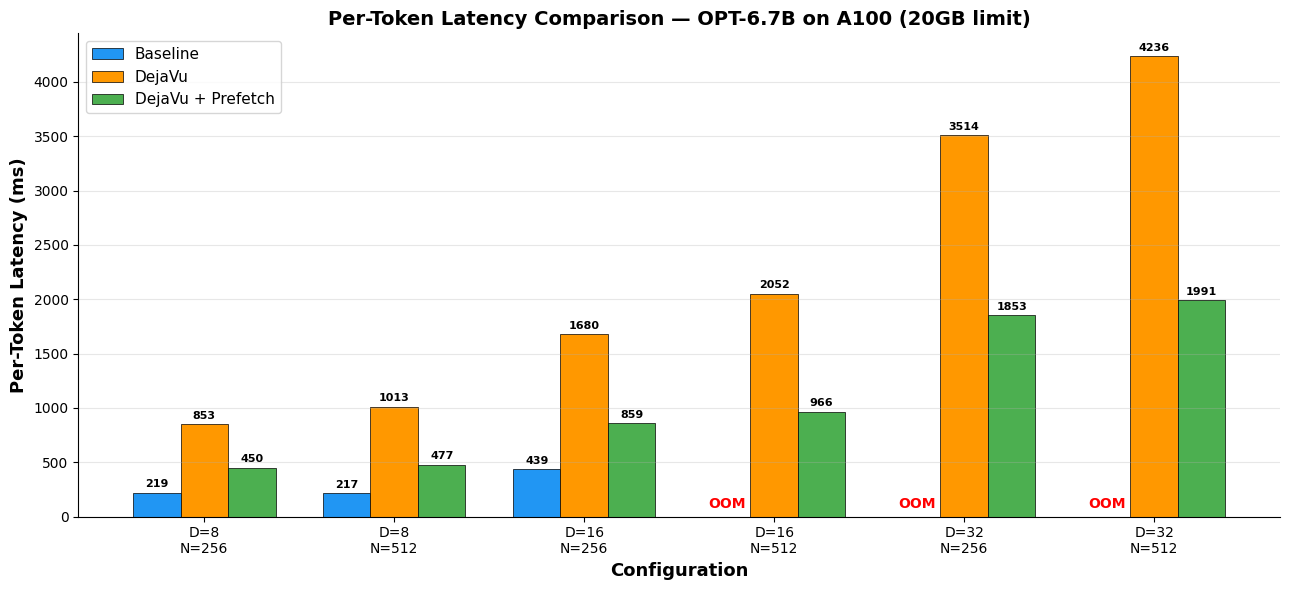

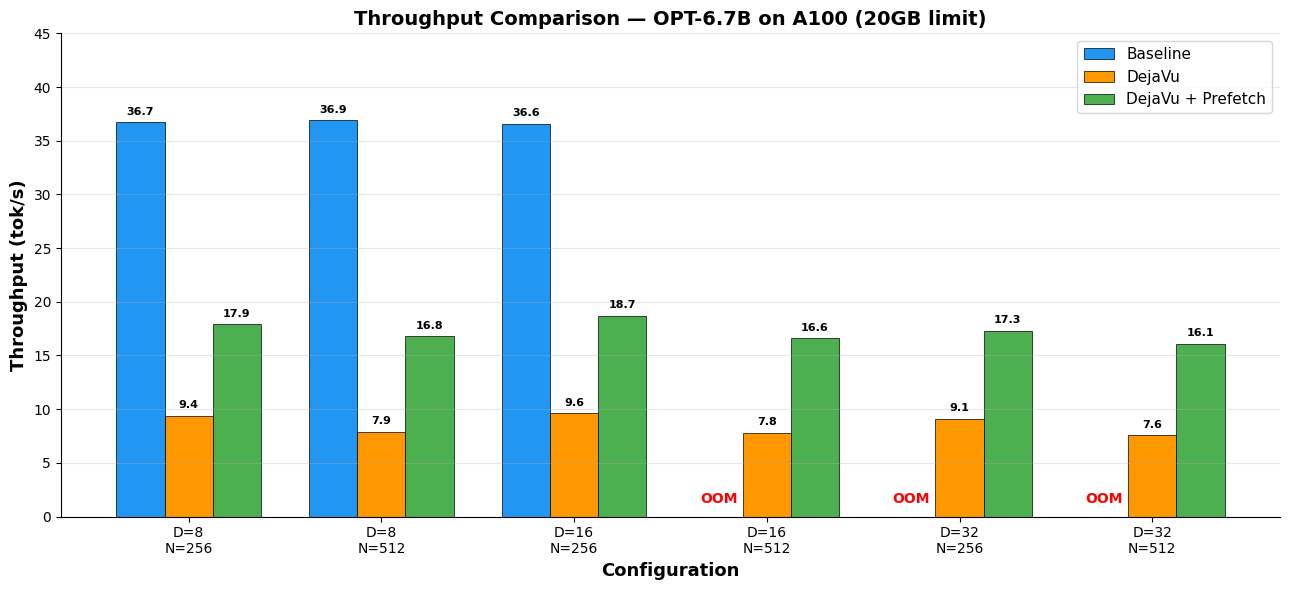

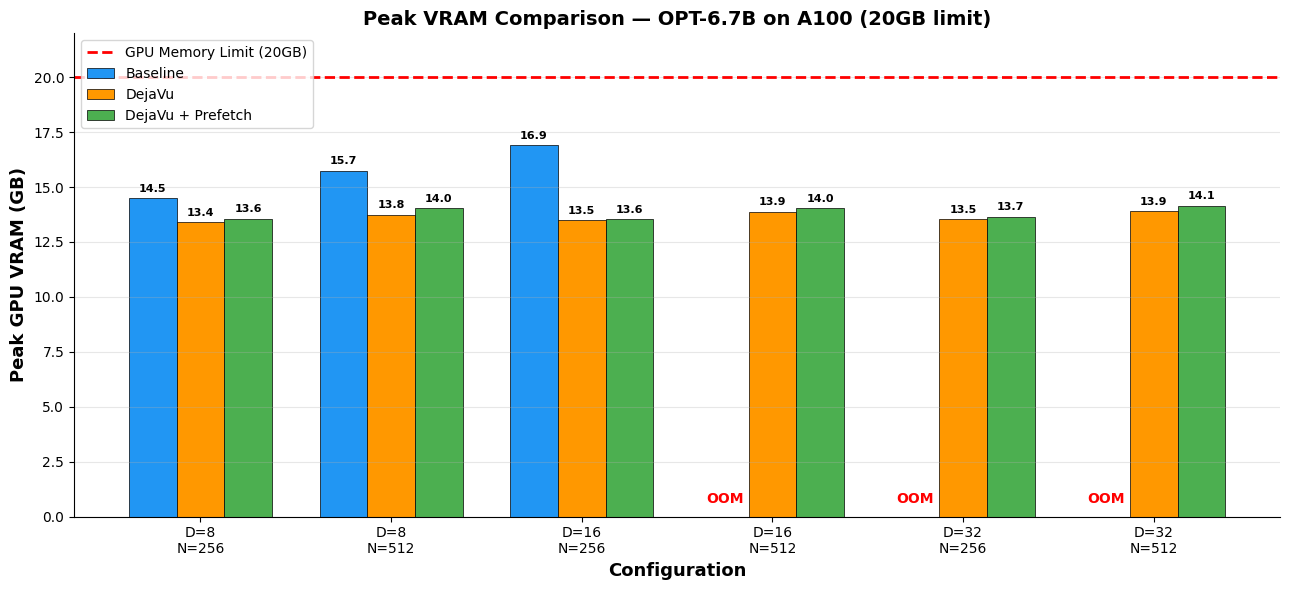

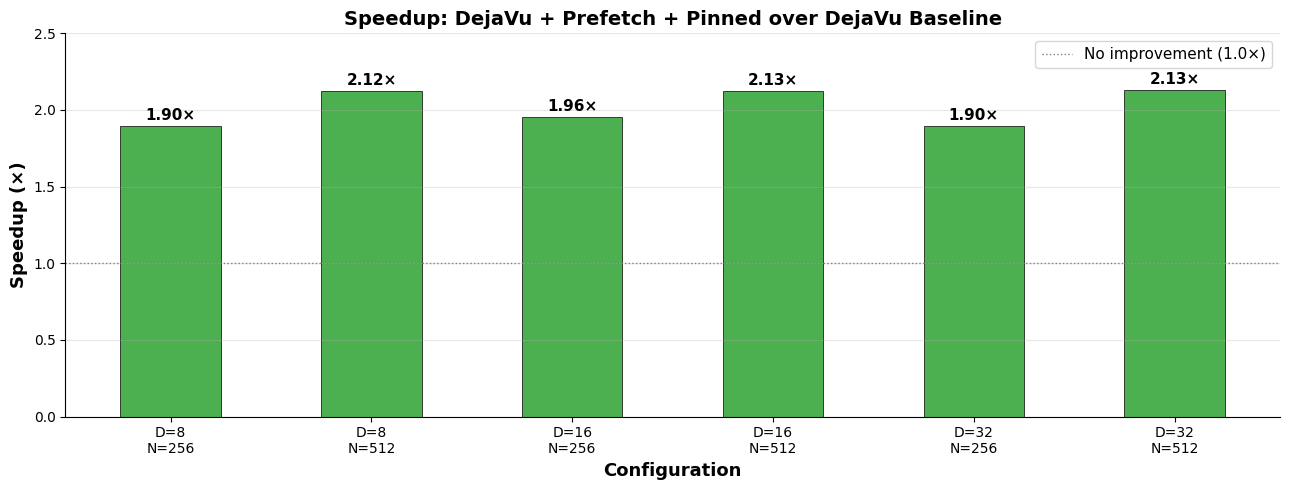

In [9]:
import matplotlib.pyplot as plt
import numpy as np

configs = ['D=8\nN=256', 'D=8\nN=512', 'D=16\nN=256', 'D=16\nN=512', 'D=32\nN=256', 'D=32\nN=512']
N_vals = [256, 512, 256, 512, 256, 512]

baseline = {
    'throughput': [36.7, 36.9, 36.6, None, None, None],
    'latency': [55.8, 111.0, 112.0, None, None, None],
    'vram': [14835, 16117, 17315, None, None, None],
}

dejavu = {
    'throughput': [9.4, 7.9, 9.6, 7.8, 9.1, 7.6],
    'latency': [217.5, 517.4, 428.4, 1048.6, 896, 2164.5],
    'vram': [13716, 14080, 13819, 14216, 13853, 14234],
}

prefetch_pin = {
    'throughput': [17.9, 16.8, 18.7, 16.6, 17.3, 16.1],
    'latency': [114.7, 243.7, 219.0, 493.4, 472.5, 1017.5],
    'vram': [13879, 14373, 13876, 14376, 13981, 14488],
    'cpu_kv': [2053.5, 3077.5, 4091.5, 6139.5, 8323.5, 12419.5],
}

# Per-token latency (ms)
baseline_ptl = [(l/(n-1))*1000 if l else None for l, n in zip(baseline['latency'], N_vals)]
dejavu_ptl = [(l/(n-1))*1000 for l, n in zip(dejavu['latency'], N_vals)]
prefetch_ptl = [(l/(n-1))*1000 for l, n in zip(prefetch_pin['latency'], N_vals)]

x = np.arange(len(configs))
width = 0.25

# ============================================
# GRAPH 1: Per-Token Latency — All 3 systems
# ============================================
fig, ax = plt.subplots(figsize=(13, 6))

b_vals = [v if v else 0 for v in baseline_ptl]
bars1 = ax.bar(x - width, b_vals, width, label='Baseline', color='#2196F3', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x, dejavu_ptl, width, label='DejaVu', color='#FF9800', edgecolor='black', linewidth=0.5)
bars3 = ax.bar(x + width, prefetch_ptl, width, label='DejaVu + Prefetch', color='#4CAF50', edgecolor='black', linewidth=0.5)

for i, v in enumerate(baseline_ptl):
    if v is None:
        ax.text(x[i] - width, 50, 'OOM', ha='center', va='bottom', fontsize=10, fontweight='bold', color='red')
        bars1[i].set_color('#FFCDD2')
        bars1[i].set_edgecolor('red')
    else:
        ax.text(x[i] - width, v + 30, f'{v:.0f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, v in enumerate(dejavu_ptl):
    ax.text(x[i], v + 30, f'{v:.0f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, v in enumerate(prefetch_ptl):
    ax.text(x[i] + width, v + 30, f'{v:.0f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Per-Token Latency (ms)', fontsize=13, fontweight='bold')
ax.set_title('Per-Token Latency Comparison — OPT-6.7B on A100 (20GB limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved per-token latency")

# ============================================
# GRAPH 2: Throughput — All 3 systems
# ============================================
fig, ax = plt.subplots(figsize=(13, 6))

b_vals = [v if v else 0 for v in baseline['throughput']]
bars1 = ax.bar(x - width, b_vals, width, label='Baseline', color='#2196F3', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x, dejavu['throughput'], width, label='DejaVu', color='#FF9800', edgecolor='black', linewidth=0.5)
bars3 = ax.bar(x + width, prefetch_pin['throughput'], width, label='DejaVu + Prefetch', color='#4CAF50', edgecolor='black', linewidth=0.5)

for i, v in enumerate(baseline['throughput']):
    if v is None:
        ax.text(x[i] - width, 1, 'OOM', ha='center', va='bottom', fontsize=10, fontweight='bold', color='red')
        bars1[i].set_color('#FFCDD2')
        bars1[i].set_edgecolor('red')
    else:
        ax.text(x[i] - width, v + 0.5, f'{v:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, v in enumerate(dejavu['throughput']):
    ax.text(x[i], v + 0.5, f'{v:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, v in enumerate(prefetch_pin['throughput']):
    ax.text(x[i] + width, v + 0.5, f'{v:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Throughput (tok/s)', fontsize=13, fontweight='bold')
ax.set_title('Throughput Comparison — OPT-6.7B on A100 (20GB limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=11)
ax.set_ylim(0, 45)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved throughput")

# ============================================
# GRAPH 3: Peak VRAM — All 3 systems
# ============================================
fig, ax = plt.subplots(figsize=(13, 6))

b_vram = [v/1024 if v else 0 for v in baseline['vram']]
d_vram = [v/1024 for v in dejavu['vram']]
p_vram = [v/1024 for v in prefetch_pin['vram']]

bars1 = ax.bar(x - width, b_vram, width, label='Baseline', color='#2196F3', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x, d_vram, width, label='DejaVu', color='#FF9800', edgecolor='black', linewidth=0.5)
bars3 = ax.bar(x + width, p_vram, width, label='DejaVu + Prefetch', color='#4CAF50', edgecolor='black', linewidth=0.5)

ax.axhline(y=20, color='red', linestyle='--', linewidth=2, label='GPU Memory Limit (20GB)')

for i, v in enumerate(baseline['vram']):
    if v is None:
        ax.text(x[i] - width, 0.5, 'OOM', ha='center', va='bottom', fontsize=10, fontweight='bold', color='red')
        bars1[i].set_color('#FFCDD2')
        bars1[i].set_edgecolor('red')
    else:
        ax.text(x[i] - width, v/1024 + 0.2, f'{v/1024:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, v in enumerate(d_vram):
    ax.text(x[i], v + 0.2, f'{v:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

for i, v in enumerate(p_vram):
    ax.text(x[i] + width, v + 0.2, f'{v:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Peak GPU VRAM (GB)', fontsize=13, fontweight='bold')
ax.set_title('Peak VRAM Comparison — OPT-6.7B on A100 (20GB limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=10, loc='upper left')
ax.set_ylim(0, 22)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved VRAM")

# ============================================
# GRAPH 4: Speedup of Prefetch+Pinned over DejaVu
# ============================================
fig, ax = plt.subplots(figsize=(13, 5))

speedup = [d/p for d, p in zip(dejavu['latency'], prefetch_pin['latency'])]

bars = ax.bar(configs, speedup, color='#4CAF50', edgecolor='black', linewidth=0.5, width=0.5)
ax.axhline(y=1.0, color='gray', linestyle=':', linewidth=1, label='No improvement (1.0×)')

for bar, v in zip(bars, speedup):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
            f'{v:.2f}×', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Speedup (×)', fontsize=13, fontweight='bold')
ax.set_title('Speedup: DejaVu + Prefetch + Pinned over DejaVu Baseline', fontsize=14, fontweight='bold')
ax.set_ylim(0, 2.5)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved speedup")

Saved!


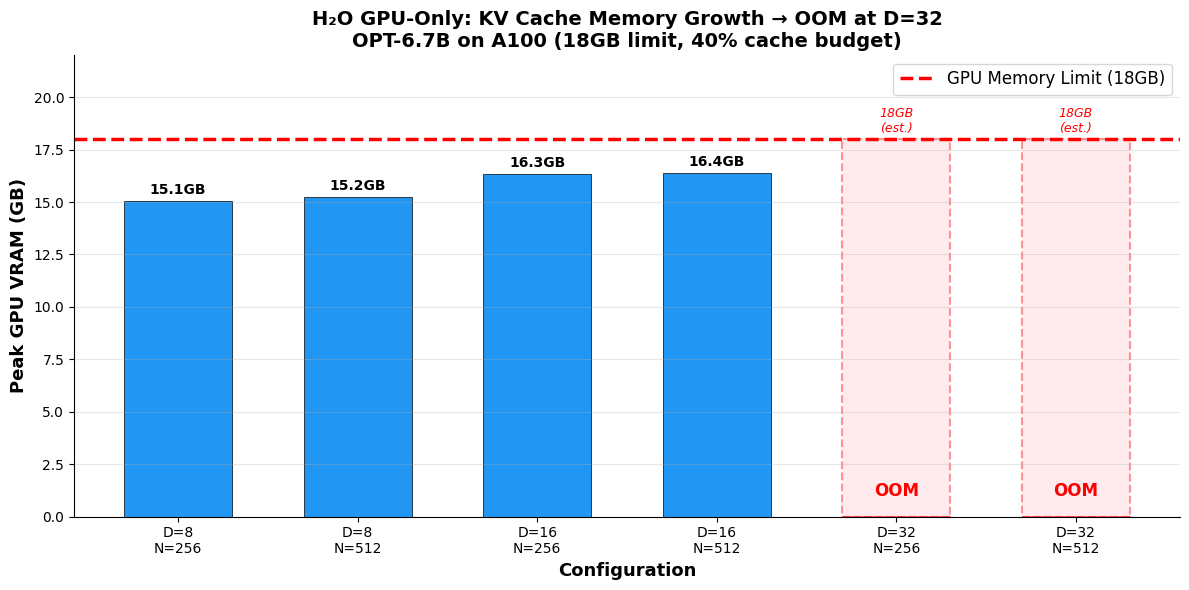

In [14]:
import matplotlib.pyplot as plt
import numpy as np

configs = ['D=8\nN=256', 'D=8\nN=512', 'D=16\nN=256', 'D=16\nN=512', 'D=32\nN=256', 'D=32\nN=512']

# H2O VRAM data (MB) — None = OOM
h2o_vram = [15421, 15597, 16733, 16760, None, None]

gpu_limit = 18  # GB

fig, ax = plt.subplots(figsize=(12, 6))

vals_gb = []
colors = []
for v in h2o_vram:
    if v is not None:
        vals_gb.append(v / 1024)
        colors.append('#2196F3')
    else:
        vals_gb.append(0)
        colors.append('#FFCDD2')

bars = ax.bar(configs, vals_gb, color=colors, edgecolor='black', linewidth=0.5, width=0.6)

# Memory limit line
ax.axhline(y=gpu_limit, color='red', linestyle='--', linewidth=2.5, label=f'GPU Memory Limit ({gpu_limit}GB)')

# Label bars
for i, v in enumerate(h2o_vram):
    if v is not None:
        ax.text(bars[i].get_x() + bars[i].get_width()/2., v/1024 + 0.2,
                f'{v/1024:.1f}GB', ha='center', va='bottom', fontsize=10, fontweight='bold')
    else:
        # Ghost bar showing estimated VRAM
        est = [None, None, None, None, 18, 18]
        if est[i]:
            ax.bar(configs[i], est[i], color='#FFCDD2', edgecolor='red',
                   linewidth=1.5, linestyle='--', alpha=0.4, width=0.6)
            ax.text(bars[i].get_x() + bars[i].get_width()/2., est[i] + 0.2,
                    f'{est[i]}GB\n(est.)', ha='center', va='bottom',
                    fontsize=9, color='red', fontstyle='italic')
        ax.text(bars[i].get_x() + bars[i].get_width()/2., 0.8,
                'OOM', ha='center', va='bottom', fontsize=12, fontweight='bold', color='red')
        bars[i].set_edgecolor('red')
        bars[i].set_linewidth(2)

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Peak GPU VRAM (GB)', fontsize=13, fontweight='bold')
ax.set_title('H₂O GPU-Only: KV Cache Memory Growth → OOM at D=32\nOPT-6.7B on A100 (18GB limit, 40% cache budget)', fontsize=14, fontweight='bold')
ax.set_ylim(0, 22)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved!")

Saved throughput
Saved per-token latency
Saved VRAM
Saved CPU KV


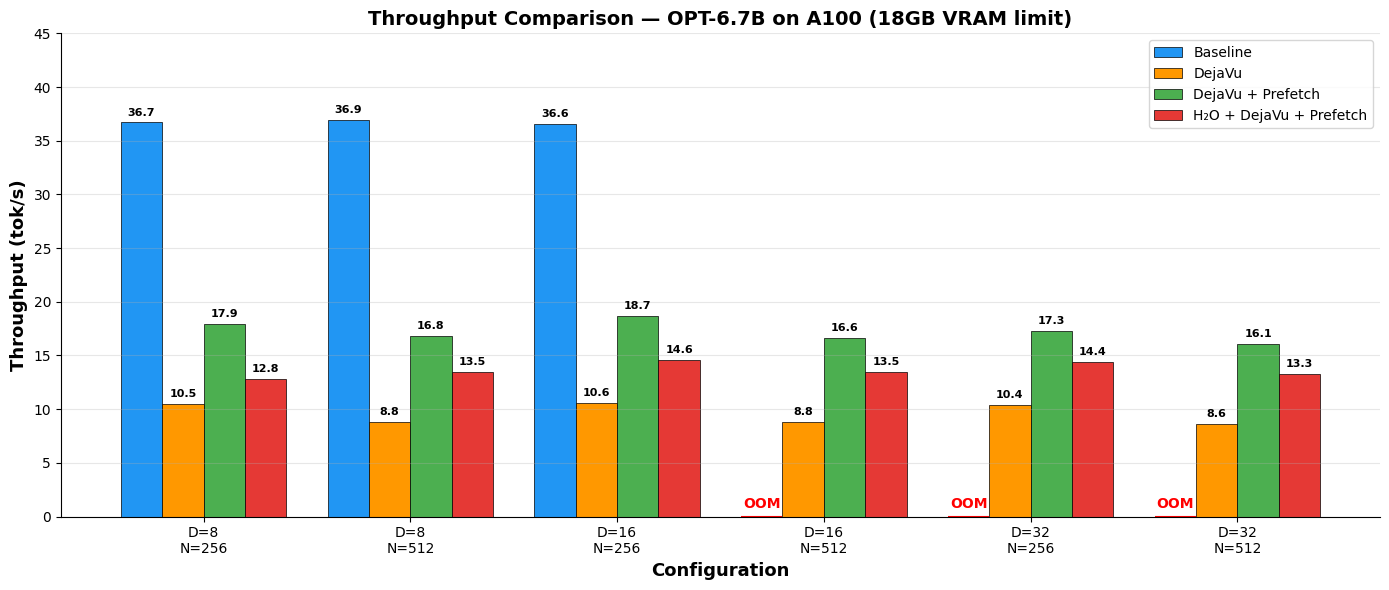

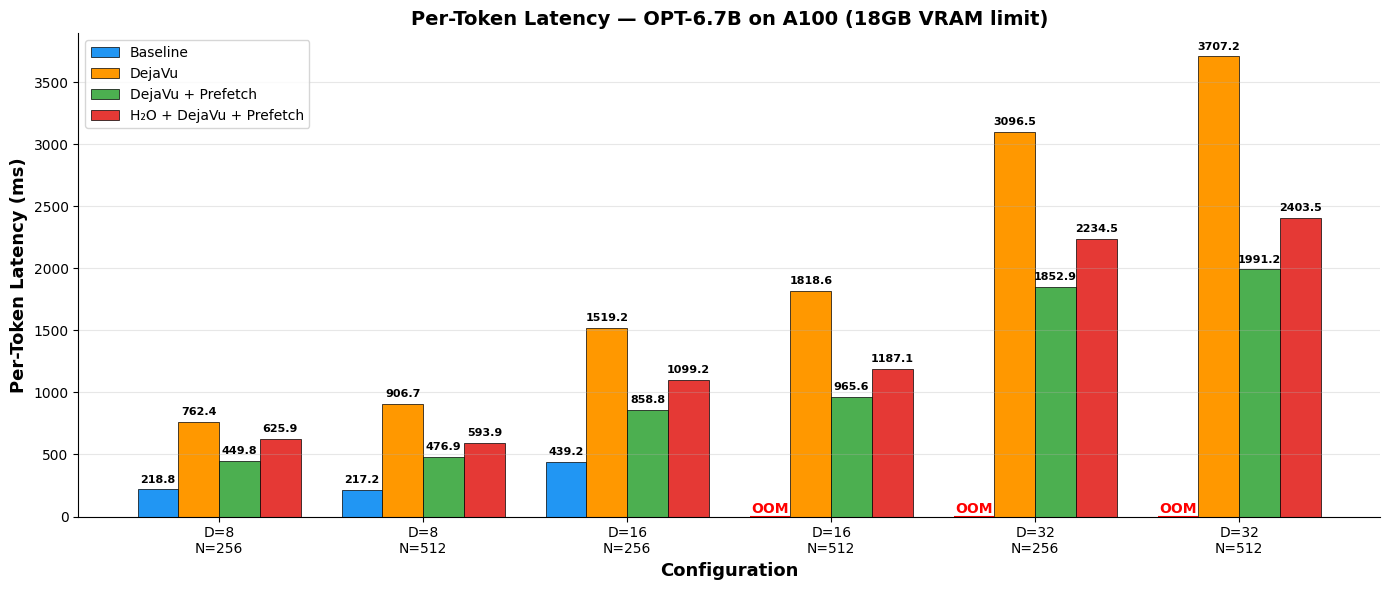

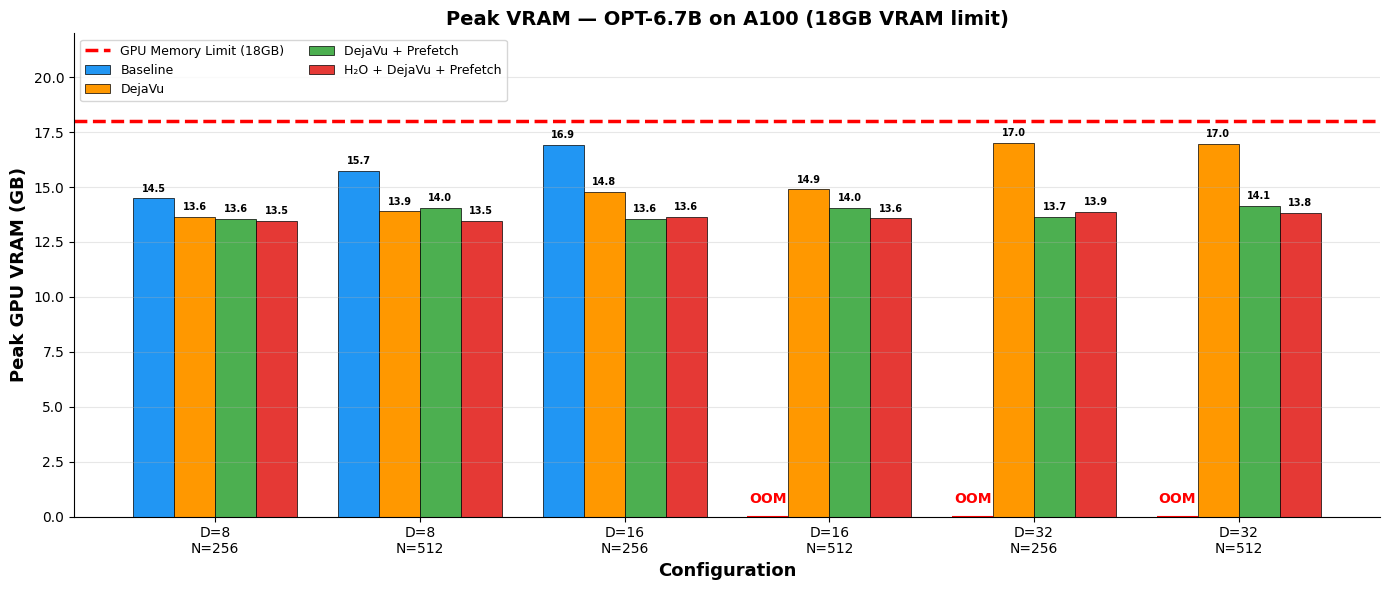

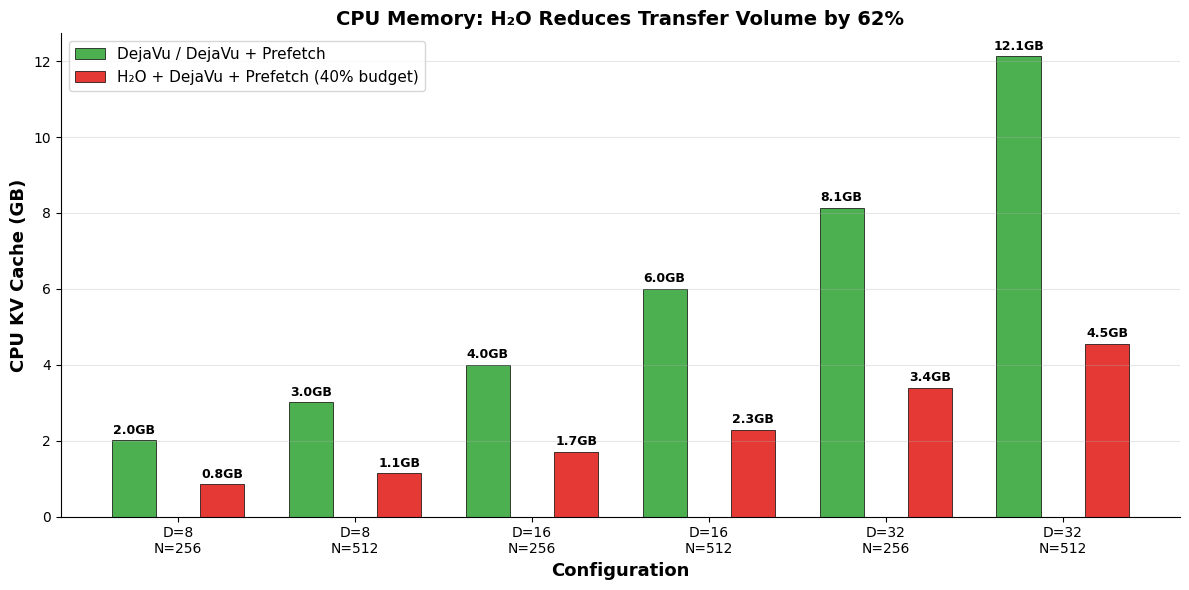

In [19]:
import matplotlib.pyplot as plt
import numpy as np

configs = ['D=8\nN=256', 'D=8\nN=512', 'D=16\nN=256', 'D=16\nN=512', 'D=32\nN=256', 'D=32\nN=512']
N_vals = [256, 512, 256, 512, 256, 512]

C_BASE = '#2196F3'
C_DEJA = '#FF9800'
C_PREF = '#4CAF50'
C_COMB = '#E53935'
C_OOM  = '#FFCDD2'

baseline = {
    'throughput': [36.7, 36.9, 36.6, None, None, None],
    'latency': [55.8, 111.0, 112.0, None, None, None],
    'vram': [14835, 16117, 17315, None, None, None],
}

dejavu = {
    'throughput': [10.5, 8.8, 10.6, 8.8, 10.4, 8.6],
    'latency': [194.4, 463.3, 387.4, 929.3, 789.6, 1894.4],
    'vram': [13950, 14222, 15151, 15247, 17434, 17363],
}

prefetch = {
    'throughput': [17.9, 16.8, 18.7, 16.6, 17.3, 16.1],
    'latency': [114.7, 243.7, 219.0, 493.4, 472.5, 1017.5],
    'vram': [13879, 14373, 13876, 14376, 13981, 14488],
}

h2o_dejavu = {
    'throughput': [12.8, 13.5, 14.6, 13.5, 14.4, 13.3],
    'latency': [159.6, 303.5, 280.3, 606.6, 569.8, 1228.2],
    'vram': [13782, 13791, 13952, 13896, 14217, 14136],
    'cpu_kv': [868, 1164, 1736, 2328, 3472, 4656],
}

def ptl(lat, n):
    return [(l/(nv-1))*1000 if l else None for l, nv in zip(lat, n)]

base_ptl = ptl(baseline['latency'], N_vals)
deja_ptl = ptl(dejavu['latency'], N_vals)
pref_ptl = ptl(prefetch['latency'], N_vals)
comb_ptl = ptl(h2o_dejavu['latency'], N_vals)

x = np.arange(len(configs))
width = 0.2

def safe(data):
    return [v if v else 0 for v in data]

def label_bars(ax, bars, data, fontsize=8):
    for i, (bar, v) in enumerate(zip(bars, data)):
        if v is None:
            ax.text(bar.get_x() + bar.get_width()/2., 0.5, 'OOM', ha='center', va='bottom',
                    fontsize=10, fontweight='bold', color='red')
            bar.set_color(C_OOM)
            bar.set_edgecolor('red')
            bar.set_linewidth(1.5)
        elif v > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + ax.get_ylim()[1]*0.01,
                    f'{v:.1f}', ha='center', va='bottom', fontsize=fontsize, fontweight='bold')

# ============================================
# GRAPH 1: Throughput
# ============================================
fig, ax = plt.subplots(figsize=(14, 6))

b1 = ax.bar(x - 1.5*width, safe(baseline['throughput']), width, label='Baseline', color=C_BASE, edgecolor='black', linewidth=0.5)
b2 = ax.bar(x - 0.5*width, safe(dejavu['throughput']), width, label='DejaVu', color=C_DEJA, edgecolor='black', linewidth=0.5)
b3 = ax.bar(x + 0.5*width, safe(prefetch['throughput']), width, label='DejaVu + Prefetch', color=C_PREF, edgecolor='black', linewidth=0.5)
b4 = ax.bar(x + 1.5*width, safe(h2o_dejavu['throughput']), width, label='H₂O + DejaVu + Prefetch', color=C_COMB, edgecolor='black', linewidth=0.5)

ax.set_ylim(0, 45)
label_bars(ax, b1, baseline['throughput'])
label_bars(ax, b2, dejavu['throughput'])
label_bars(ax, b3, prefetch['throughput'])
label_bars(ax, b4, h2o_dejavu['throughput'])

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Throughput (tok/s)', fontsize=13, fontweight='bold')
ax.set_title('Throughput Comparison — OPT-6.7B on A100 (18GB VRAM limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=10, loc='upper right')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved throughput")

# ============================================
# GRAPH 2: Per-Token Latency
# ============================================
fig, ax = plt.subplots(figsize=(14, 6))

b1 = ax.bar(x - 1.5*width, safe(base_ptl), width, label='Baseline', color=C_BASE, edgecolor='black', linewidth=0.5)
b2 = ax.bar(x - 0.5*width, safe(deja_ptl), width, label='DejaVu', color=C_DEJA, edgecolor='black', linewidth=0.5)
b3 = ax.bar(x + 0.5*width, safe(pref_ptl), width, label='DejaVu + Prefetch', color=C_PREF, edgecolor='black', linewidth=0.5)
b4 = ax.bar(x + 1.5*width, safe(comb_ptl), width, label='H₂O + DejaVu + Prefetch', color=C_COMB, edgecolor='black', linewidth=0.5)

label_bars(ax, b1, base_ptl)
label_bars(ax, b2, deja_ptl)
label_bars(ax, b3, pref_ptl)
label_bars(ax, b4, comb_ptl)

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Per-Token Latency (ms)', fontsize=13, fontweight='bold')
ax.set_title('Per-Token Latency — OPT-6.7B on A100 (18GB VRAM limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=10, loc='upper left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved per-token latency")

# ============================================
# GRAPH 3: Peak VRAM
# ============================================
fig, ax = plt.subplots(figsize=(14, 6))

def to_gb(data):
    return [v/1024 if v else None for v in data]

b1 = ax.bar(x - 1.5*width, safe(to_gb(baseline['vram'])), width, label='Baseline', color=C_BASE, edgecolor='black', linewidth=0.5)
b2 = ax.bar(x - 0.5*width, safe(to_gb(dejavu['vram'])), width, label='DejaVu', color=C_DEJA, edgecolor='black', linewidth=0.5)
b3 = ax.bar(x + 0.5*width, safe(to_gb(prefetch['vram'])), width, label='DejaVu + Prefetch', color=C_PREF, edgecolor='black', linewidth=0.5)
b4 = ax.bar(x + 1.5*width, safe(to_gb(h2o_dejavu['vram'])), width, label='H₂O + DejaVu + Prefetch', color=C_COMB, edgecolor='black', linewidth=0.5)

ax.axhline(y=18, color='red', linestyle='--', linewidth=2.5, label='GPU Memory Limit (18GB)')

ax.set_ylim(0, 22)
label_bars(ax, b1, to_gb(baseline['vram']), fontsize=7)
label_bars(ax, b2, to_gb(dejavu['vram']), fontsize=7)
label_bars(ax, b3, to_gb(prefetch['vram']), fontsize=7)
label_bars(ax, b4, to_gb(h2o_dejavu['vram']), fontsize=7)

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('Peak GPU VRAM (GB)', fontsize=13, fontweight='bold')
ax.set_title('Peak VRAM — OPT-6.7B on A100 (18GB VRAM limit)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=9, loc='upper left', ncol=2)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved VRAM")

# ============================================
# GRAPH 4: CPU KV Memory
# ============================================
fig, ax = plt.subplots(figsize=(12, 6))

deja_cpu = [2053.5, 3077.5, 4091.5, 6139.5, 8323.5, 12419.5]
comb_cpu = [868, 1164, 1736, 2328, 3472, 4656]

width2 = 0.25
b1 = ax.bar(x - width2, [v/1024 for v in deja_cpu], width2, label='DejaVu / DejaVu + Prefetch', color=C_PREF, edgecolor='black', linewidth=0.5)
b2 = ax.bar(x + width2, [v/1024 for v in comb_cpu], width2, label='H₂O + DejaVu + Prefetch (40% budget)', color=C_COMB, edgecolor='black', linewidth=0.5)

for bar, v in zip(b1, deja_cpu):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
            f'{v/1024:.1f}GB', ha='center', va='bottom', fontsize=9, fontweight='bold')

for bar, v in zip(b2, comb_cpu):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
            f'{v/1024:.1f}GB', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel('Configuration', fontsize=13, fontweight='bold')
ax.set_ylabel('CPU KV Cache (GB)', fontsize=13, fontweight='bold')
ax.set_title('CPU Memory: H₂O Reduces Transfer Volume by 62%', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(configs, fontsize=10)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
print("Saved CPU KV")